# Практична робота 18. Множинна лінійна регресія
**Варіант 1 (м. Київ)**

Цей ноутбук містить повний розв'язок завдань з побудови множинної лінійної регресії, перевірки VIF, аналізу R² проти Adjusted R², діагностики залишків та порівняння з простою регресією.

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
import matplotlib.pyplot as plt

np.random.seed(42)
city = "Київ"
mean_temp = 9.5
amplitude = 14.0
hum_base = 74

rows = []
for month in range(1, 13):
    temp = mean_temp + amplitude * np.cos((month - 7) / 12 * 2 * np.pi) + np.random.normal(0, 1.0)
    humidity = hum_base + np.random.normal(0, 5.0)
    if temp < 8:
        opal_days = 30
    elif temp < 12:
        opal_days = 15
    else:
        opal_days = 0

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )
    rows.append({
        "місто": city, "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)
print(heating.head())

  місто  місяць  температура  вологість  опалювальні_дні  витрати_на_опалення
0  Київ       1         -4.0       73.3               30                364.7
1  Київ       2         -1.1       72.8               30                325.1
2  Київ       3          4.1       77.8               30                277.9
3  Київ       4         10.0       71.7               15                183.1
4  Київ       5         16.7       64.4                0                 62.1


## Завдання 1 & 2. Модель із двома предикторами та інтерпретація

In [2]:
X1 = sm.add_constant(heating[["температура", "вологість"]])
y1 = heating["витрати_на_опалення"]

model1 = sm.OLS(y1, X1).fit()
print(model1.summary())

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.976
Model:                             OLS   Adj. R-squared:                  0.970
Method:                  Least Squares   F-statistic:                     179.6
Date:                 Sun, 11 Oct 2026   Prob (F-statistic):           5.58e-08
Time:                         15:57:05   Log-Likelihood:                -52.453
No. Observations:                   12   AIC:                             110.9
Df Residuals:                        9   BIC:                             112.4
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         223.1684    122.718      1

## Завдання 3. Перевірка мультиколінеарності через VIF

In [3]:
vif_data = pd.DataFrame()
vif_data["feature"] = X1.columns
vif_data["VIF"] = [variance_inflation_factor(X1.values, i) for i in range(X1.shape[1])]
print(vif_data)

       feature      VIF
0        const  1.00000
1  температура  1.55295
2    вологість  1.55295


## Завдання 4. Третій предиктор: R² проти Adjusted R²

In [4]:
X2 = sm.add_constant(heating[["температура", "вологість", "опалювальні_дні"]])
y2 = heating["витрати_на_опалення"]

model2 = sm.OLS(y2, X2).fit()
print(f"Модель 1 — R²: {model1.rsquared:.4f}, Adj R²: {model1.rsquared_adj:.4f}")
print(f"Модель 2 — R²: {model2.rsquared:.4f}, Adj R²: {model2.rsquared_adj:.4f}")

Модель 1 — R²: 0.9756, Adj R²: 0.9701
Модель 2 — R²: 0.9916, Adj R²: 0.9884


## Завдання 5. Діагностика залишків

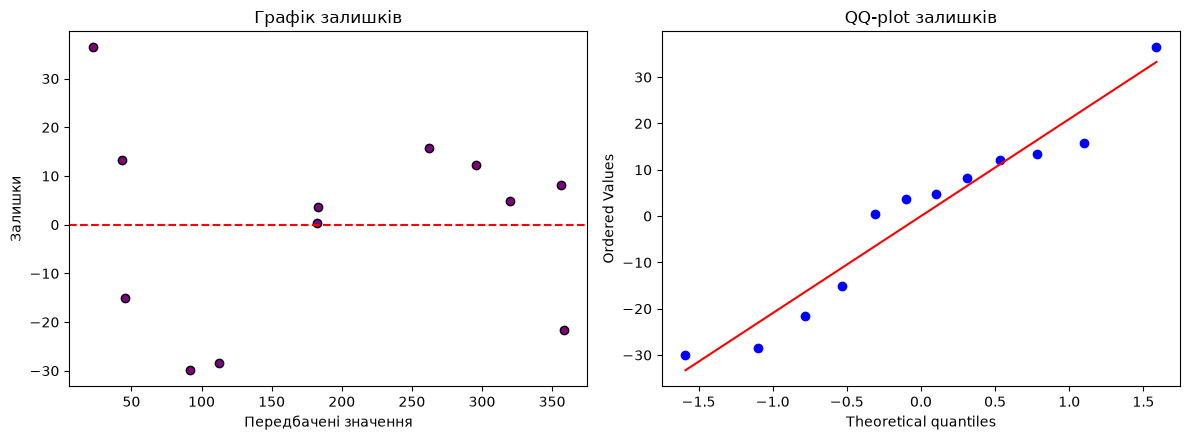

Шеміро-Вілк: статистика = 0.9388, p-value = 0.4828


In [5]:
fitted_vals = model1.fittedvalues
residuals = model1.resid

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.scatter(fitted_vals, residuals, color="purple", edgecolor="black")
ax1.axhline(0, color="red", linestyle="--")
ax1.set_xlabel("Передбачені значення")
ax1.set_ylabel("Залишки")
ax1.set_title("Графік залишків")

stats.probplot(residuals, dist="norm", plot=ax2)
ax2.set_title("QQ-plot залишків")
plt.tight_layout()
plt.show()

shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Шеміро-Вілк: статистика = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}")